# Exercise 1
How large is large? Iterative methods are relevant for large scale problems, but how large
is large? Take N = 2n for n = 7, 8, 9, . . . and generate a random matrix K ∈ RN ×N and
a random vector y.
- (a) How large an N can you handle if you want to compute the SVD in a few seconds?
How does the time grow when N is doubled?
- (b) A dense N × N matrix in double precision takes 8N 2 bytes. For which N does K no
longer fit in the memory of your computer?
- (c) An image with m × m pixels has N = m2 unknowns. How much memory does the
dense matrix of a linear operator on the image need for m = 64, 128, 256, 512? What
do you conclude about the way we must implement K for images?

k= 5  --> 2^k =  32
Time to calc. SVD:  0.0  min
k= 6  --> 2^k =  64
Time to calc. SVD:  0.0  min
k= 7  --> 2^k =  128
Time to calc. SVD:  0.0015519000007770956  min
k= 8  --> 2^k =  256
Time to calc. SVD:  0.00572190000093542  min
k= 9  --> 2^k =  512
Time to calc. SVD:  0.03587240001070313  min
k= 10  --> 2^k =  1024
Time to calc. SVD:  0.09651709999889135  min
k= 11  --> 2^k =  2048
Time to calc. SVD:  0.3174526000220794  min
k= 12  --> 2^k =  4096
Time to calc. SVD:  1.712742400006391  min


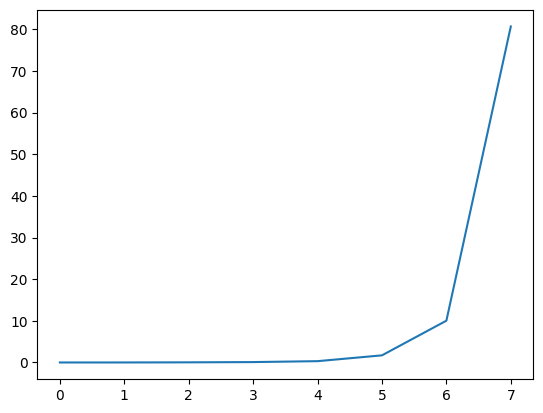

AttributeError: module 'numpy' has no attribute 'float128'

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt

N = 2**3

a = 5
b = 13

np.random.seed(42)
time_array = np.zeros(b-a)

for k in range(a,b):
    N = 2**k
    print("k=",k," --> 2^k = ", N)
    
    start = time.perf_counter()

    K = np.random.rand(N,N)
    U,mu,Vt = np.linalg.svd(K)

    end = time.perf_counter()
    time_array[k-a] = end - start
    print("Time to calc. SVD: ",round(time_array[k-7],4)," min")

    del K, U, mu, Vt
    

plt.plot(time_array)
plt.show()


$$
N_{max} = \left\lfloor\sqrt{\frac{\text{available RAM in Bytes}}{8}}\right\rfloor
$$

my Laptop: 16 GB $\rightarrow$ $16\cdot 10^9$ Byte

so my $N_max = \lfloor\sqrt{2\cdot 10^9}\rfloor = \lfloor 2\sqrt{5} \cdot 10^4 \rfloor =44 721$ 

since $2^15 = 32768$ and $2^16 = 65536 \quad \rightarrow \quad k=15$ 

In [3]:
# b)
#K_precision = np.random.rand(N,N,dtype=np.float128)

# import numpy as np

# for k in [13, 14, 15,16]:
#     N = 2**k

#     print(f"Erstelle Matrix für k={k}, N={N} ...")

#     K = np.random.rand(N, N)

#     print(f"Speicherbedarf: {K.nbytes / 2**30:.2f} GiB")

#     del K
#     print("Matrix gelöscht.\n")


# Hier den verfügbaren Arbeitsspeicher eintragen
ram_gib = 16
ram_bytes = ram_gib * 2**30

n = 7

while 8 * (2**n)**2 <= ram_bytes:
    n += 1

print(f"Erste Zweierpotenz, die nicht hineinpasst: N = 2^{n} = {2**n}")
print(f"Speicherbedarf: {8 * (2**n)**2 / 2**30:.1f} GiB")

Erste Zweierpotenz, die nicht hineinpasst: N = 2^16 = 65536
Speicherbedarf: 32.0 GiB


In [4]:
#c) - skipped